# Assignment 10 - Midsem Solutions and BERT Language Identification

**Name:** Tanu Meena  
**Roll number:** U23AI076

Part A solves midsem questions 2, 4, and 5. Part B fine-tunes the actual
multilingual BERT base model on the saved 23-language dataset used in Lab 6,
then compares against all seven earlier classifiers on the same test split.
The setup, split separation, macro-F1, predictions, and reports follow Lab 6.

In [8]:
import hashlib
import json
import math
import os
import random
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

LAB_DIR = (Path(__file__).resolve().parent if '__file__' in globals() else
           Path.cwd() if (Path.cwd() / 'Assignment10_Midsem_BERT.py').exists()
           else Path.cwd() / 'Lab10')
ROOT = LAB_DIR.parent
OUT = LAB_DIR / 'assignment10_artifacts'
for sub in ['models', 'plots']:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

## Part A, Question 2: Beam search with k=2

A hypothesis has score `P(w1)...P(wt | w1...w(t-1))`. At each step, expand
only the two retained prefixes and keep the two highest cumulative scores.
No length normalization is specified, so this trace uses raw probabilities.
Each supplied conditional distribution sums to one, so unlisted vocabulary
items have probability zero. The table includes those zero-score expansions.

At t=1, `cat` (0.5) and `sat` (0.3) survive. `mat` (0.2) is pruned.
At t=2, `cat sat` (0.30) and `sat mat` (0.21) survive.
At t=3, `cat sat mat` (0.24) and `sat mat </s>` (0.189) survive.

**The highest-scoring sequence at the specified three-step horizon is
`cat sat mat`, with probability 0.24.** It is not EOS-terminated. If the
output must be a completed sentence, the best completed retained candidate
is `sat mat </s>`, with probability 0.189. The paper gives no t=4
probabilities, so an EOS completion of `cat sat mat` cannot be calculated.

We ignore `P(cat|mat)` and `P(sat|mat)` because the one-word prefix `mat`
was pruned at t=1. `sat mat` does survive later, but its next-token
probabilities are `P(w | sat mat)`, not `P(w | mat)`.

In [9]:
beam_trace = []
tables = {
    (): {'cat': .5, 'sat': .3, 'mat': .2},
    ('cat',): {'sat': .6, 'mat': .3, '</s>': .1},
    ('sat',): {'cat': .2, 'mat': .7, '</s>': .1},
    ('cat', 'sat'): {'mat': .8, '</s>': .2},
    ('sat', 'mat'): {'cat': .1, '</s>': .9}}
beam = [((), 1.0)]
beam_vocabulary = ['cat', 'sat', 'mat', '</s>']
for step in range(1, 4):
    expanded = []
    for prefix, prefix_probability in beam:
        for word in beam_vocabulary:
            conditional = tables[prefix].get(word, 0.0)
            expanded.append((prefix + (word,), prefix_probability * conditional,
                             prefix_probability, conditional))
    expanded.sort(key=lambda row: (-row[1], row[0]))
    for rank, (sequence, score, prefix_score, conditional) in enumerate(expanded, 1):
        beam_trace.append({'t': step, 'hypothesis': ' '.join(sequence),
                           'prefix_probability': prefix_score,
                           'conditional_probability': conditional,
                           'cumulative_probability': score, 'retained': rank <= 2})
    beam = [(row[0], row[1]) for row in expanded[:2]]
beam_df = pd.DataFrame(beam_trace)
assert np.isclose(beam[0][1], .24) and np.isclose(beam[1][1], .189)
beam_df.to_csv(OUT / 'q2_beam_search.csv', index=False)
display(beam_df.round(6))

,t,hypothesis,prefix_probability,conditional_probability,cumulative_probability,retained
0,1,cat,1.00,0.5,0.500,True
1,1,sat,1.00,0.3,0.300,True
2,1,mat,1.00,0.2,0.200,False
3,1,</s>,1.00,0.0,0.000,False
4,2,cat sat,0.50,0.6,0.300,True
5,2,sat mat,0.30,0.7,0.210,True
6,2,cat mat,0.50,0.3,0.150,False
7,2,sat cat,0.30,0.2,0.060,False
8,2,cat </s>,0.50,0.1,0.050,False
9,2,sat </s>,0.30,0.1,0.030,False


## Part A, Question 4: BPE for two merges

Word frequencies are `low:5`, `lower:2`, `lowest:3`, `new:2`, `newest:1`,
and `widest:3`. Start with characters and an end-of-word marker `</w>`.
Pair counts are weighted by word frequency and never cross word boundaries.

In the first iteration, `(l,o)` and `(o,w)` both occur 10 times. We resolve
this tie by lexicographic order and merge `(l,o) -> lo`. After recounting,
`(lo,w)` occurs 10 times and is the second merge: `(lo,w) -> low`.
Other tie conventions can produce `(o,w) -> ow` followed by `(l,ow) -> low`.
Both are valid when the convention is stated.

The initial vocabulary is `{</w>, d, e, i, l, n, o, r, s, t, w}`.
The tokenizer vocabulary after two merges adds `lo` and `low`. Original
characters remain available for encoding unseen words, even if some no
longer occur separately in this small corpus.

BPE encodes an unseen word using learned merges and remaining characters.
For example, unseen `lowernew` becomes `low e r n e w </w>`.
An entirely unseen character requires an unknown token or byte fallback;
ordinary character BPE cannot create a character missing from its vocabulary.

In [10]:
corpus = 'low lower low lower lowest low lowest low lowest low new newest widest widest new widest'
word_counts = Counter(corpus.split())
vocabulary = {tuple(word) + ('</w>',): count for word, count in word_counts.items()}
initial_symbols = sorted({symbol for word in vocabulary for symbol in word})
merges = []
pair_tables = []
for iteration in range(2):
    pairs = Counter()
    for word, frequency in vocabulary.items():
        for pair in zip(word, word[1:]):
            pairs[pair] += frequency
    best = min(pairs, key=lambda pair: (-pairs[pair], pair))
    pair_tables.extend({'iteration': iteration+1, 'pair': ' + '.join(pair),
                        'weighted_count': count, 'selected': pair == best}
                       for pair, count in sorted(pairs.items(), key=lambda item: (-item[1], item[0])))
    updated = {}
    for word, frequency in vocabulary.items():
        output, index = [], 0
        while index < len(word):
            if index+1 < len(word) and (word[index], word[index+1]) == best:
                output.append(''.join(best))
                index += 2
            else:
                output.append(word[index])
                index += 1
        updated[tuple(output)] = updated.get(tuple(output), 0) + frequency
    vocabulary = updated
    merges.append(best)
assert word_counts == {'low': 5, 'lower': 2, 'lowest': 3, 'new': 2, 'newest': 1, 'widest': 3}
assert merges == [('l', 'o'), ('lo', 'w')]
pair_df = pd.DataFrame(pair_tables)
pair_df.to_csv(OUT / 'q4_pair_counts.csv', index=False)
display(pd.DataFrame(word_counts.items(), columns=['word', 'frequency']))
display(pair_df)
display(pd.DataFrame([{'segmentation': ' '.join(word), 'frequency': frequency}
                      for word, frequency in vocabulary.items()]))
print('Tokenizer vocabulary:', initial_symbols + ['lo', 'low'])

,word,frequency
0,low,5
1,lower,2
2,lowest,3
3,new,2
4,newest,1
5,widest,3


,iteration,pair,weighted_count,selected
0,1,l + o,10,True
1,1,o + w,10,False
2,1,e + s,7,False
3,1,s + t,7,False
4,1,t + </w>,7,False
5,1,w + </w>,7,False
6,1,w + e,6,False
7,1,d + e,3,False
8,1,e + w,3,False
9,1,i + d,3,False


,segmentation,frequency
0,low </w>,5
1,low e r </w>,2
2,low e s t </w>,3
3,n e w </w>,2
4,n e w e s t </w>,1
5,w i d e s t </w>,3


Tokenizer vocabulary: ['</w>', 'd', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w', 'lo', 'low']


## Part A, Question 5: TF-IDF, class vectors, and Doc2Vec

We use raw term frequency `tf(t,d)=count(t,d)` and unsmoothed natural-log
inverse document frequency `idf(t)=ln(4/df(t))`. No sentence markers or
vector normalization are added. Every present term occurs once in a document.
If TF is instead divided by document length, every value below is divided
by four, because all documents contain four words.

`is` occurs in all four documents, so its IDF is zero. `learning` and
`useful` occur in three; `machine` and `language` in two; `powerful` and
`processing` in one. A class vector is the arithmetic mean of its document
vectors. Cosine similarity to these centroids can classify a new TF-IDF
document vector. Compute its weights using the training vocabulary and IDF.

**Doc2Vec architecture: PV-DM (Distributed Memory).** A trainable document-ID
vector is combined with the context-word vectors, and a softmax predicts the
next word. Backpropagation learns document and word embeddings jointly.
The document vector acts as a memory of its topic. For a new document,
freeze the learned word/output parameters and optimize its new document
vector from its words. Doc2Vec vectors are learned dense features rather
than averages of TF-IDF weights.

,term,document_frequency,idf
0,machine,2,0.693147
1,learning,3,0.287682
2,is,4,0.000000
3,useful,3,0.287682
4,powerful,1,1.386294
5,language,2,0.693147
6,processing,1,1.386294


,machine,learning,is,useful,powerful,language,processing
D1,0.693147,0.287682,0.0,0.287682,0.000000,0.000000,0.000000
D2,0.693147,0.287682,0.0,0.000000,1.386294,0.000000,0.000000
D3,0.000000,0.287682,0.0,0.287682,0.000000,0.693147,0.000000
D4,0.000000,0.000000,0.0,0.287682,0.000000,0.693147,1.386294


,machine,learning,is,useful,powerful,language,processing
Technology,0.693147,0.287682,0.0,0.143841,0.693147,0.000000,0.000000
Language,0.000000,0.143841,0.0,0.287682,0.000000,0.693147,0.693147


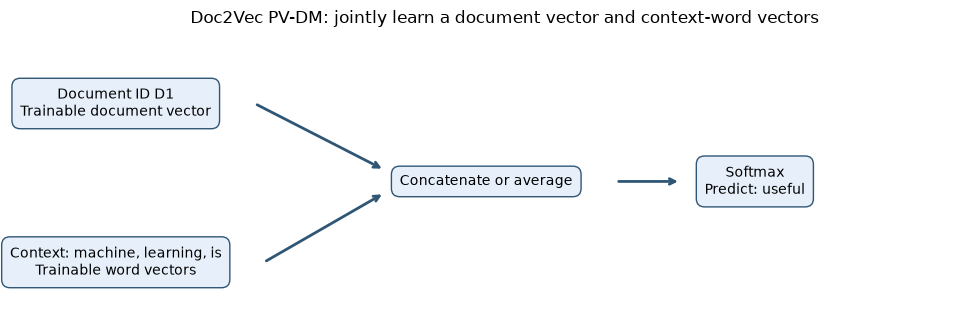

In [11]:
documents = ['machine learning is useful', 'machine learning is powerful',
             'learning language is useful', 'language processing is useful']
classes = ['Technology', 'Technology', 'Language', 'Language']
terms = list(dict.fromkeys(' '.join(documents).split()))
tf = np.array([[doc.split().count(term) for term in terms] for doc in documents])
df = (tf > 0).sum(0)
idf = np.log(len(documents) / df)
tfidf = tf * idf
assert np.isclose(idf[terms.index('is')], 0)
idf_table = pd.DataFrame({'term': terms, 'document_frequency': df, 'idf': idf})
tfidf_table = pd.DataFrame(tfidf, index=['D1', 'D2', 'D3', 'D4'], columns=terms)
centroid_table = pd.DataFrame({label: tfidf[np.array(classes) == label].mean(0)
                               for label in ['Technology', 'Language']}, index=terms).T
idf_table.to_csv(OUT / 'q5_idf.csv', index=False)
tfidf_table.to_csv(OUT / 'q5_document_tfidf.csv')
centroid_table.to_csv(OUT / 'q5_class_centroids.csv')
display(idf_table.round(6))
display(tfidf_table.round(6))
display(centroid_table.round(6))
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.axis('off')
boxes = [(0.08, .75, 'Document ID D1\nTrainable document vector'),
         (0.08, .2, 'Context: machine, learning, is\nTrainable word vectors'),
         (.48, .48, 'Concatenate or average'),
         (.77, .48, 'Softmax\nPredict: useful')]
for x, y, label in boxes:
    ax.text(x, y, label, ha='center', va='center', transform=ax.transAxes,
            bbox={'boxstyle': 'round,pad=.6', 'facecolor': '#e7f0fa', 'edgecolor': '#305675'})
for start, end in [((.23, .75), (.37, .52)), ((.24, .2), (.37, .44)), ((.62, .48), (.69, .48))]:
    ax.annotate('', xy=end, xytext=start, xycoords='axes fraction',
                arrowprops={'arrowstyle': '->', 'color': '#305675', 'lw': 2})
ax.set_title('Doc2Vec PV-DM: jointly learn a document vector and context-word vectors')
fig.tight_layout()
fig.savefig(OUT / 'plots' / 'q5_doc2vec_pvdm.png', dpi=180)
display(fig)
plt.close(fig)

## Part B, 1. Reuse the exact Lab 6 language-identification splits

Lab 6 reconstructed Assignment 1's IndicCorpV2 samples with the original
sampling procedure. We reuse those saved JSONL files directly: 36,800 train,
4,600 validation and 4,600 test, with 1,600/200/200 examples per language.
Their SHA-256 hashes must match Lab 6's manifest before training starts.
Reusing them allows a paired comparison with the earlier classifiers.

We retain the prior split even where it contains duplicate texts, so that
the comparison remains exact. The overlap audit is reported explicitly.
Any existing leakage also affects the earlier baseline scores.

In [12]:
SEED = 42
MODEL_ID = 'google-bert/bert-base-multilingual-cased'
REVISION = '3f076fdb1ab68d5b2880cb87a0886f315b8146f8'
EPOCHS = int(os.getenv('LAB10_EPOCHS', '1'))
MAX_LENGTH = 64
BATCH_SIZE = int(os.getenv('LAB10_BATCH_SIZE', '16'))
LEARNING_RATE = 3e-5
torch.set_num_threads(int(os.getenv('LAB_THREADS', '4')))
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
DATA = ROOT / 'assignment6_artifacts' / 'data'
manifest = json.loads((DATA / 'manifest.json').read_text())
label_to_id = json.loads((ROOT / 'assignment6_artifacts' / 'labels.json').read_text())
languages = [label for label, index in sorted(label_to_id.items(), key=lambda item: item[1])]

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')

splits = {}
split_hashes = {}
for split in ['train', 'validation', 'test']:
    file = DATA / f'{split}.jsonl'
    split_hashes[split] = sha256(file)
    assert split_hashes[split] == manifest['split_sha256'][split]
    records = [json.loads(line) for line in file.read_text(encoding='utf-8').splitlines()]
    splits[split] = pd.DataFrame(records)
    assert set(splits[split].label) == set(languages)
assert [len(splits[x]) for x in ['train', 'validation', 'test']] == [36800, 4600, 4600]
train_texts = set(splits['train'].text)
audit = {split: {'rows': len(data), 'unique_texts': data.text.nunique(),
                 'rows_also_in_train': int(data.text.isin(train_texts).sum()) if split != 'train' else None}
         for split, data in splits.items()}
save_json(OUT / 'data_manifest.json', {'source': manifest, 'split_sha256': split_hashes,
                                      'labels': label_to_id, 'duplicate_audit': audit})
display(pd.DataFrame(audit).T)

,rows,unique_texts,rows_also_in_train
train,36800.0,35875.0,NaN
validation,4600.0,4534.0,155.0
test,4600.0,4553.0,110.0


## Part B, 2. Tokenize with multilingual BERT

We use the original, cased, **12-layer multilingual BERT base** checkpoint.
It was pretrained on 104 Wikipedia languages and supports several Indian
languages. Coverage is not guaranteed for all 23 dataset languages or scripts,
so unknown-token rates are reported per language. No transliteration is used.

Inputs are WordPiece tokenized, with `[CLS]` and `[SEP]`. Dynamic padding
reduces computation. The limit is 64 pieces, set before training; the audit
reports truncated sentences. Lab 6 used up to 96 whitespace words for its
RNNs, so this is a comparison of complete model pipelines, not equal context
lengths or equal compute. Vocabulary pretraining is external to this split.

In [13]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)
encoded_splits = {}
token_audit = []
for split, frame in splits.items():
    full = tokenizer(frame.text.tolist(), truncation=False, add_special_tokens=True)
    lengths = np.array([len(ids) for ids in full['input_ids']])
    encoded_splits[split] = tokenizer(frame.text.tolist(), truncation=True,
                                     max_length=MAX_LENGTH, add_special_tokens=True)
    unknown = np.array([ids.count(tokenizer.unk_token_id) for ids in full['input_ids']])
    for language in languages:
        mask = (frame.label == language).to_numpy()
        token_audit.append({'split': split, 'language': language, 'sentences': int(mask.sum()),
                            'truncated_sentences': int((lengths[mask] > MAX_LENGTH).sum()),
                            'mean_tokens': float(lengths[mask].mean()),
                            'unknown_token_rate': float(unknown[mask].sum() / (lengths[mask]-2).sum())})
token_audit = pd.DataFrame(token_audit)
token_audit.to_csv(OUT / 'tokenization_audit.csv', index=False)
display(token_audit.loc[token_audit.split == 'test'].round(4))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (557 > 512). Running this sequence through the model will result in indexing errors


,split,language,sentences,truncated_sentences,mean_tokens,unknown_token_rate
46,test,asm_Beng,200,63,61.490,0.0267
47,test,ben_Beng,200,16,33.215,0.0519
48,test,brx_Deva,200,77,62.785,0.0081
49,test,doi_Deva,200,29,32.745,0.0070
50,test,gom_Deva,200,14,31.460,0.0015
51,test,guj_Gujr,200,38,47.030,0.0002
52,test,hin_Deva,200,15,34.435,0.0034
53,test,kan_Knda,200,30,42.110,0.0026
54,test,kas_Arab,200,55,59.105,0.1073
55,test,mai_Deva,200,16,38.940,0.0081


## Part B, 3. Fine-tune all BERT parameters

`[CLS] -> BERT pooler -> dropout -> 23-way linear classifier` is trained
with cross-entropy. All pretrained encoder parameters and the new classifier
receive gradients. AdamW uses learning rate 3e-5, weight decay 0.01, 10% warmup,
linear decay and gradient clipping at 1.0. The default CPU experiment is one
complete pass through all 36,800 training sentences, rather than a frozen
encoder with a separately trained classifier. Set LAB10_EPOCHS before the run
for a larger training budget. The best epoch is selected by validation
macro-F1, and test predictions are computed only afterward.

In [14]:
settings = {'model': MODEL_ID, 'revision': REVISION, 'seed': SEED, 'epochs': EPOCHS,
            'max_length': MAX_LENGTH, 'batch_size': BATCH_SIZE, 'learning_rate': LEARNING_RATE,
            'weight_decay': .01, 'data_sha256': split_hashes, 'labels': label_to_id,
            'torch': torch.__version__, 'device': DEVICE.type, 'mixed_precision': USE_AMP}
save_json(OUT / 'experiment_config.json', settings)
completion = OUT / 'completed_run.json'
previous = json.loads(completion.read_text()) if completion.exists() else {}
checkpoint = OUT / 'models' / 'best_bert'
reuse = (previous.get('settings') == settings and (checkpoint / 'model.safetensors').exists()
         and previous.get('checkpoint_sha256') == sha256(checkpoint / 'model.safetensors')
         and (OUT / 'evaluation_metrics.json').exists()
         and previous.get('metrics_sha256') == sha256(OUT / 'evaluation_metrics.json')
         and all((OUT / f'{split}_predictions.csv').exists() for split in ['validation', 'test']))

def batches(split, shuffled=False):
    count = len(splits[split])
    encoded = encoded_splits[split]
    order = np.random.permutation(count) if shuffled else np.arange(count)
    # Shuffle first, then sort inside small local buckets. Every row is visited.
    if shuffled:
        lengths = np.array([len(ids) for ids in encoded['input_ids']])
        order = np.concatenate([bucket[np.argsort(lengths[bucket], kind='stable')]
                                for bucket in [order[i:i+512] for i in range(0, count, 512)]])
    for start in range(0, count, BATCH_SIZE):
        indices = order[start:start+BATCH_SIZE]
        rows = [{key: encoded[key][int(i)] for key in encoded} for i in indices]
        batch = tokenizer.pad(rows, padding=True, return_tensors='pt')
        batch = {key: value.to(DEVICE) for key, value in batch.items()}
        labels = torch.tensor([label_to_id[splits[split].label.iloc[int(i)]] for i in indices],
                              dtype=torch.long, device=DEVICE)
        yield indices, batch, labels

def evaluate(model, split):
    model.eval()
    predicted = np.empty(len(splits[split]), dtype=np.int64)
    total_loss = 0.
    with torch.inference_mode():
        for indices, batch, labels in batches(split):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                output = model(**batch, labels=labels)
            total_loss += output.loss.item() * len(indices)
            predicted[indices] = output.logits.argmax(-1).cpu().numpy()
    gold = splits[split].label.map(label_to_id).to_numpy()
    return {'loss': total_loss / len(gold), 'accuracy': accuracy_score(gold, predicted),
            'macro_f1': f1_score(gold, predicted, labels=range(23), average='macro', zero_division=0)}, predicted

if not reuse:
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID, revision=REVISION, num_labels=23, id2label=dict(enumerate(languages)),
        label2id=label_to_id).to(DEVICE)
    assert model.config.num_hidden_layers == 12
    assert all(parameter.requires_grad for parameter in model.parameters())
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=.01, foreach=False)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    total_steps = math.ceil(len(splits['train']) / BATCH_SIZE) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(.1*total_steps), total_steps)
    history, best_f1 = [], -1.
    started = time.perf_counter()
    for epoch in range(1, EPOCHS+1):
        model.train()
        total_loss, seen = 0., 0
        for step, (indices, batch, labels) in enumerate(batches('train', shuffled=True), 1):
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                output = model(**batch, labels=labels)
            scaler.scale(output.loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            total_loss += output.loss.item() * len(indices)
            seen += len(indices)
            if step % 100 == 0:
                print(f'epoch {epoch}, {seen}/36800 sentences, loss {total_loss/seen:.4f}, '
                      f'{time.perf_counter()-started:.1f}s', flush=True)
        assert seen == 36800
        metrics, _ = evaluate(model, 'validation')
        history.append({'epoch': epoch, 'train_loss': total_loss/seen,
                        'validation_loss': metrics['loss'], 'validation_accuracy': metrics['accuracy'],
                        'validation_macro_f1': metrics['macro_f1'],
                        'elapsed_seconds': time.perf_counter()-started})
        if metrics['macro_f1'] > best_f1:
            best_f1 = metrics['macro_f1']
            best_epoch = epoch
            model.save_pretrained(checkpoint)
            tokenizer.save_pretrained(checkpoint)
        pd.DataFrame(history).to_csv(OUT / 'training_history.csv', index=False)
        print('Validation:', metrics, flush=True)
    elapsed = time.perf_counter()-started
    del optimizer, scheduler, model
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    save_json(OUT / 'selected_model.json', {'best_epoch': best_epoch,
                                           'validation_macro_f1': best_f1,
                                           'training_seconds': elapsed})
    model = AutoModelForSequenceClassification.from_pretrained(checkpoint).to(DEVICE)
    summary = {}
    for split in ['validation', 'test']:
        metrics, prediction = evaluate(model, split)
        summary[split] = metrics
        gold = splits[split].label.map(label_to_id).to_numpy()
        frame = splits[split].rename(columns={'label': 'gold_language'}).copy()
        frame['predicted_language'] = [languages[int(i)] for i in prediction]
        frame['correct'] = prediction == gold
        frame.to_csv(OUT / f'{split}_predictions.csv', index=False)
        pd.DataFrame(confusion_matrix(gold, prediction, labels=range(23)),
                     index=languages, columns=languages).to_csv(OUT / f'{split}_confusion.csv')
        per_class = classification_report(gold, prediction, labels=range(23),
                                          target_names=languages, output_dict=True, zero_division=0)
        pd.DataFrame(per_class).T.to_csv(OUT / f'{split}_per_class.csv')
    del model
    save_json(OUT / 'evaluation_metrics.json', summary)
    save_json(completion, {'settings': settings,
                           'checkpoint_sha256': sha256(checkpoint / 'model.safetensors'),
                           'metrics_sha256': sha256(OUT / 'evaluation_metrics.json')})
else:
    print('Reusing completed matching BERT experiment.')
summary = json.loads((OUT / 'evaluation_metrics.json').read_text())
selected = json.loads((OUT / 'selected_model.json').read_text())
display(pd.DataFrame(summary).T)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.

epoch 1, 1600/36800 sentences, loss 2.9690, 270.0s
epoch 1, 3200/36800 sentences, loss 2.3480, 565.2s
epoch 1, 4800/36800 sentences, loss 1.7968, 877.2s
epoch 1, 6400/36800 sentences, loss 1.4773, 1201.6s
epoch 1, 8000/36800 sentences, loss 1.2709, 1544.1s


KeyboardInterrupt: 

## Part B, 4. Compare with the earlier seven classifiers

All scores below refer to the same held-out 4,600 rows. Macro-F1 weights each
of the 23 languages equally. The BERT training budget is deliberately small;
external multilingual pretraining does not guarantee a win over FastText.
Models differ in tokenization, embedding coverage, context limit, training
schedule and capacity. We describe the measured differences without claiming
a controlled ablation of any single component.

,Model,Validation_Macro_F1,Test_Macro_F1,Test_Accuracy
0,FastText classification,0.9479,0.9417,0.9417
7,Multilingual BERT base (fine-tuned),0.9062,0.8950,0.8963
1,LSTM,0.8938,0.8877,0.8876
2,GRU,0.8937,0.8851,0.8852
3,MLP (n=1),0.8842,0.8696,0.8776
4,MLP (n=2),0.8833,0.8707,0.8791
5,MLP (n=0),0.8758,0.8606,0.8698
6,Logistic regression,0.8570,0.8360,0.8511


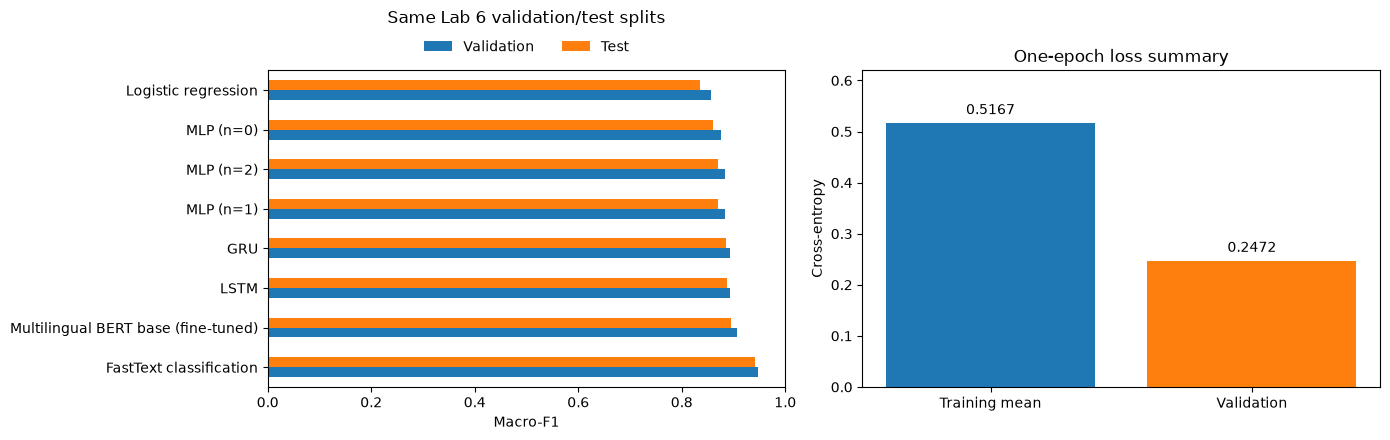

# Assignment 10 - Midsem and BERT Language Identification

Tanu Meena, U23AI076

## Midsem Question 2

The beams are `cat`/`sat` at t=1, `cat sat`/`sat mat` at t=2, and
`cat sat mat` (0.24)/`sat mat </s>` (0.189) at t=3. The highest three-step
sequence is `cat sat mat`. It has not ended; `sat mat </s>` is the best completed
candidate. No t=4 probabilities are supplied. P(cat|mat) and P(sat|mat)
are irrelevant because the prefix mat was pruned at t=1.

|   t | hypothesis     |   prefix_probability |   conditional_probability |   cumulative_probability | retained   |
|----:|:---------------|---------------------:|--------------------------:|-------------------------:|:-----------|
|   1 | `cat`          |                 1    |                       0.5 |                    0.5   | True       |
|   1 | `sat`          |                 1    |                       0.3 |                    0.3   | True       |
|   1 | `mat`          |                 1    |                       0.2 |                    0.2   | False      |
|   1 | `</s>`         |                 1    |                       0   |                    0     | False      |
|   2 | `cat sat`      |                 0.5  |                       0.6 |                    0.3   | True       |
|   2 | `sat mat`      |                 0.3  |                       0.7 |                    0.21  | True       |
|   2 | `cat mat`      |                 0.5  |                       0.3 |                    0.15  | False      |
|   2 | `sat cat`      |                 0.3  |                       0.2 |                    0.06  | False      |
|   2 | `cat </s>`     |                 0.5  |                       0.1 |                    0.05  | False      |
|   2 | `sat </s>`     |                 0.3  |                       0.1 |                    0.03  | False      |
|   2 | `cat cat`      |                 0.5  |                       0   |                    0     | False      |
|   2 | `sat sat`      |                 0.3  |                       0   |                    0     | False      |
|   3 | `cat sat mat`  |                 0.3  |                       0.8 |                    0.24  | True       |
|   3 | `sat mat </s>` |                 0.21 |                       0.9 |                    0.189 | True       |
|   3 | `cat sat </s>` |                 0.3  |                       0.2 |                    0.06  | False      |
|   3 | `sat mat cat`  |                 0.21 |                       0.1 |                    0.021 | False      |
|   3 | `cat sat cat`  |                 0.3  |                       0   |                    0     | False      |
|   3 | `cat sat sat`  |                 0.3  |                       0   |                    0     | False      |
|   3 | `sat mat mat`  |                 0.21 |                       0   |                    0     | False      |
|   3 | `sat mat sat`  |                 0.21 |                       0   |                    0     | False      |

## Midsem Question 4

Word frequencies: low=5, lower=2, lowest=3, new=2, newest=1, widest=3.
Two frequency-weighted merges, with lexicographic tie-breaking:
(l,o) -> lo (count 10), followed by (lo,w) -> low (count 10).
Initial character vocabulary: `['</w>', 'd', 'e', 'i', 'l', 'n', 'o', 'r', 's', 't', 'w']`. Add `lo` and `low`.
Unseen `lowernew` becomes `low e r n e w </w>`. Unseen characters need
an unknown token or byte fallback.

## Midsem Question 5

TF is raw count; IDF is ln(4/df), without smoothing or normalization.

| term       |   document_frequency |      idf |
|:-----------|---------------------:|---------:|
| machine    |                    2 | 0.693147 |
| learning   |                    3 | 0.287682 |
| is         |                    4 | 0.000000 |
| useful     |                    3 | 0.287682 |
| powerful   |                    1 | 1.386294 |
| language   |                    2 | 0.693147 |
| processing |                    1 | 1.386294 |

|    |   machine |   learning |       is |   useful |   powerful |   language |   processing |
|:---|----------:|-----------:|---------:|---------:|-----------:|-----------:|-------------:|
| D1 |  0.693147 |   0.287682 | 0.000000 | 0.287682 |   0.000000 |   0.000000 |     0.000000 |
| D2 |  0.693147 |   0.287682 | 0.000000 | 0.000000 |   1.386294 |   0.000000 |     0.000000 |
| D3 |  0.000000 |   0.287682 | 0.000000 | 0.287682 |   0.000000 |   0.693147 |     0.000000 |
| D4 |  0.000000 |   0.000000 | 0.000000 | 0.287682 |   0.000000 |   0.693147 |     1.386294 |

Class vectors are means of their document TF-IDF vectors:

|            |   machine |   learning |       is |   useful |   powerful |   language |   processing |
|:-----------|----------:|-----------:|---------:|---------:|-----------:|-----------:|-------------:|
| Technology |  0.693147 |   0.287682 | 0.000000 | 0.143841 |   0.693147 |   0.000000 |     0.000000 |
| Language   |  0.000000 |   0.143841 | 0.000000 | 0.287682 |   0.000000 |   0.693147 |     0.693147 |

Doc2Vec PV-DM jointly learns a document-ID vector and context-word vectors
to predict a target word using softmax. See plots/q5_doc2vec_pvdm.png.
New document inference optimizes its vector while fixing the word and output weights.

## BERT experiment

Pretrained model: google-bert/bert-base-multilingual-cased, revision 3f076fdb1ab68d5b2880cb87a0886f315b8146f8. Original 12-layer base
architecture, all parameters fine-tuned. Exactly 36,800 training, 4,600
validation and 4,600 test examples from the saved Lab 6 JSONL files.
Split hashes were verified against Lab 6. All 23 labels are retained.
Training: 1 complete epoch(s), batch 16, learning rate 3e-5,
AdamW weight decay 0.01, 10% warmup, linear decay, gradient clipping 1.0.
Device: cuda; CUDA mixed precision: True.
Best validation epoch: 1.
Maximum context: 64 WordPiece tokens. Test truncations:
699/4,600.

| Model | Validation macro-F1 | Test macro-F1 | Test accuracy |
| --- | ---: | ---: | ---: |
| FastText classification | 0.9479 | 0.9417 | 0.9417 |
| Multilingual BERT base (fine-tuned) | 0.9062 | 0.8950 | 0.8963 |
| LSTM | 0.8938 | 0.8877 | 0.8876 |
| GRU | 0.8937 | 0.8851 | 0.8852 |
| MLP (n=1) | 0.8842 | 0.8696 | 0.8776 |
| MLP (n=2) | 0.8833 | 0.8707 | 0.8791 |
| MLP (n=0) | 0.8758 | 0.8606 | 0.8698 |
| Logistic regression | 0.8570 | 0.8360 | 0.8511 |

The BERT-minus-FastText test macro-F1 difference is
-0.0467. This reports the observed run;
it does not establish which model wins under larger training budgets.
The short training schedule, different context limits, external pretraining,
and uneven script coverage affect interpretation.

The retained prior splits contain 155
validation rows and 110 test rows whose exact
texts occur in training. Earlier baselines share this limitation; these scores
should not be interpreted as a fully duplicate-free generalization estimate.
Per-language unknown-token and truncation rates are in tokenization_audit.csv.

## References

- Supplied midsem question paper and Lab 10 assignment PDF in this folder.
- Lab 6: ../Assignment6_Language_Identification.ipynb and saved artifacts.
- Multilingual BERT: https://huggingface.co/google-bert/bert-base-multilingual-cased
- BERT: https://arxiv.org/abs/1810.04805


In [ ]:
baseline_path = ROOT / 'assignment6_artifacts' / 'assignment6_classifier_comparison.csv'
comparison = pd.read_csv(baseline_path)
bert_row = {'Model': 'Multilingual BERT base (fine-tuned)',
            'Validation_Macro_F1': summary['validation']['macro_f1'],
            'Test_Macro_F1': summary['test']['macro_f1'],
            'Validation_Accuracy': summary['validation']['accuracy'],
            'Test_Accuracy': summary['test']['accuracy'],
            'Best_Epoch': selected['best_epoch'], 'Training_Seconds': selected['training_seconds'],
            'Notes': f'All parameters fine-tuned; {EPOCHS} epoch(s); 64 WordPiece tokens'}
comparison = pd.concat([comparison, pd.DataFrame([bert_row])], ignore_index=True)
comparison = comparison.sort_values('Validation_Macro_F1', ascending=False)
comparison.to_csv(OUT / 'classifier_comparison.csv', index=False)
display(comparison[['Model', 'Validation_Macro_F1', 'Test_Macro_F1', 'Test_Accuracy']].round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
comparison.set_index('Model')[['Validation_Macro_F1', 'Test_Macro_F1']].rename(
    columns={'Validation_Macro_F1': 'Validation', 'Test_Macro_F1': 'Test'}).plot.barh(ax=axes[0])
axes[0].set(xlabel='Macro-F1', xlim=(0, 1), ylabel='')
axes[0].legend(loc='lower center', bbox_to_anchor=(.5, 1.01), ncol=2, frameon=False)
axes[0].set_title('Same Lab 6 validation/test splits', pad=34)
history = pd.read_csv(OUT / 'training_history.csv')
if len(history) == 1:
    bars = axes[1].bar(['Training mean', 'Validation'],
        [history.train_loss.iloc[0], history.validation_loss.iloc[0]], color=['#1f77b4', '#ff7f0e'])
    axes[1].bar_label(bars, fmt='%.4f', padding=4)
    axes[1].set(ylabel='Cross-entropy', title='One-epoch loss summary', ylim=(0, history.train_loss.iloc[0]*1.2))
else:
    axes[1].plot(history.epoch, history.train_loss, marker='o', label='Training')
    axes[1].plot(history.epoch, history.validation_loss, marker='o', label='Validation')
    axes[1].set(xlabel='Epoch', ylabel='Cross-entropy', title='BERT fine-tuning')
    axes[1].legend()
fig.tight_layout()
fig.savefig(OUT / 'plots' / 'bert_comparison.png', dpi=180)
display(fig)
plt.close(fig)
table = ['| Model | Validation macro-F1 | Test macro-F1 | Test accuracy |',
         '| --- | ---: | ---: | ---: |']
for row in comparison.itertuples(index=False):
    table.append(f'| {row.Model} | {row.Validation_Macro_F1:.4f} | {row.Test_Macro_F1:.4f} | {row.Test_Accuracy:.4f} |')
fasttext_f1 = float(comparison.loc[comparison.Model == 'FastText classification', 'Test_Macro_F1'].iloc[0])
report = f'''# Assignment 10 - Midsem and BERT Language Identification

Tanu Meena, U23AI076

## Midsem Question 2

The beams are `cat`/`sat` at t=1, `cat sat`/`sat mat` at t=2, and
`cat sat mat` (0.24)/`sat mat </s>` (0.189) at t=3. The highest three-step
sequence is `cat sat mat`. It has not ended; `sat mat </s>` is the best completed
candidate. No t=4 probabilities are supplied. P(cat|mat) and P(sat|mat)
are irrelevant because the prefix mat was pruned at t=1.

{beam_df.assign(hypothesis=beam_df.hypothesis.map(lambda value: '`'+value+'`')).to_markdown(index=False)}

## Midsem Question 4

Word frequencies: low=5, lower=2, lowest=3, new=2, newest=1, widest=3.
Two frequency-weighted merges, with lexicographic tie-breaking:
(l,o) -> lo (count 10), followed by (lo,w) -> low (count 10).
Initial character vocabulary: `{initial_symbols}`. Add `lo` and `low`.
Unseen `lowernew` becomes `low e r n e w </w>`. Unseen characters need
an unknown token or byte fallback.

## Midsem Question 5

TF is raw count; IDF is ln(4/df), without smoothing or normalization.

{idf_table.to_markdown(index=False, floatfmt='.6f')}

{tfidf_table.to_markdown(floatfmt='.6f')}

Class vectors are means of their document TF-IDF vectors:

{centroid_table.to_markdown(floatfmt='.6f')}

Doc2Vec PV-DM jointly learns a document-ID vector and context-word vectors
to predict a target word using softmax. See plots/q5_doc2vec_pvdm.png.
New document inference optimizes its vector while fixing the word and output weights.

## BERT experiment

Pretrained model: {MODEL_ID}, revision {REVISION}. Original 12-layer base
architecture, all parameters fine-tuned. Exactly 36,800 training, 4,600
validation and 4,600 test examples from the saved Lab 6 JSONL files.
Split hashes were verified against Lab 6. All 23 labels are retained.
Training: {EPOCHS} complete epoch(s), batch {BATCH_SIZE}, learning rate 3e-5,
AdamW weight decay 0.01, 10% warmup, linear decay, gradient clipping 1.0.
Device: {DEVICE.type}; CUDA mixed precision: {USE_AMP}.
Best validation epoch: {selected['best_epoch']}.
Maximum context: {MAX_LENGTH} WordPiece tokens. Test truncations:
{int(token_audit.loc[token_audit.split == 'test', 'truncated_sentences'].sum())}/4,600.

{chr(10).join(table)}

The BERT-minus-FastText test macro-F1 difference is
{summary['test']['macro_f1']-fasttext_f1:+.4f}. This reports the observed run;
it does not establish which model wins under larger training budgets.
The short training schedule, different context limits, external pretraining,
and uneven script coverage affect interpretation.

The retained prior splits contain {audit['validation']['rows_also_in_train']}
validation rows and {audit['test']['rows_also_in_train']} test rows whose exact
texts occur in training. Earlier baselines share this limitation; these scores
should not be interpreted as a fully duplicate-free generalization estimate.
Per-language unknown-token and truncation rates are in tokenization_audit.csv.

## References

- Supplied midsem question paper and Lab 10 assignment PDF in this folder.
- Lab 6: ../Assignment6_Language_Identification.ipynb and saved artifacts.
- Multilingual BERT: https://huggingface.co/google-bert/bert-base-multilingual-cased
- BERT: https://arxiv.org/abs/1810.04805
'''
(OUT / 'assignment10_report.md').write_text(report, encoding='utf-8')
display(Markdown(report))